<center>
    <img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/Logos/organization_logo/organization_logo.png" width="300" alt="cognitiveclass.ai logo">
</center>


#### Import the required libraries we need for the lab.


In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#### Read the dataset in the csv file from the URL


In [28]:
boston_df=pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv')

#### Add your code below following the instructions given in the course to complete the peer graded assignment


In [29]:

print(boston_df.shape)
print(boston_df.columns.tolist())
boston_df.head()


(506, 14)
['Unnamed: 0', 'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT', 'MEDV']


,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


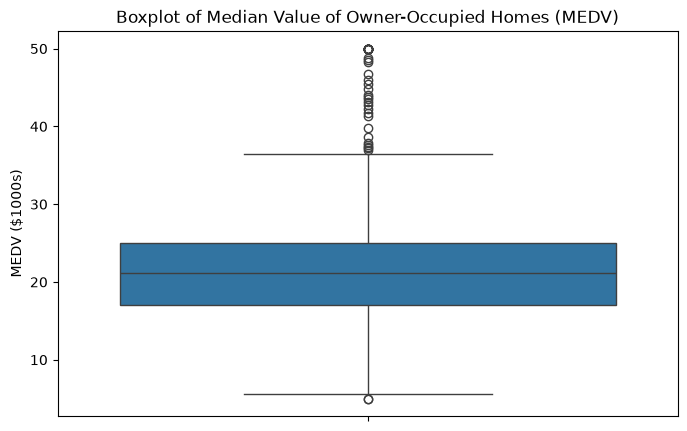

In [30]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(y=boston_df['MEDV'])
plt.title('Boxplot of Median Value of Owner-Occupied Homes (MEDV)')
plt.ylabel('MEDV ($1000s)')
plt.show()


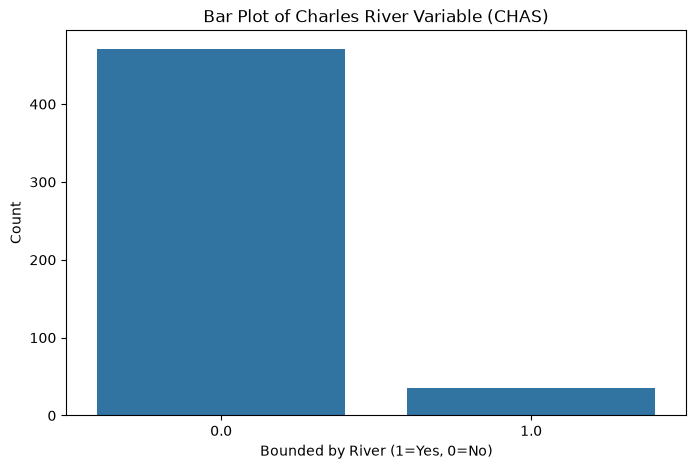

In [31]:

plt.figure(figsize=(8, 5))
sns.countplot(x='CHAS', data=boston_df)
plt.title('Bar Plot of Charles River Variable (CHAS)')
plt.xlabel('Bounded by River (1=Yes, 0=No)')
plt.ylabel('Count')
plt.show()


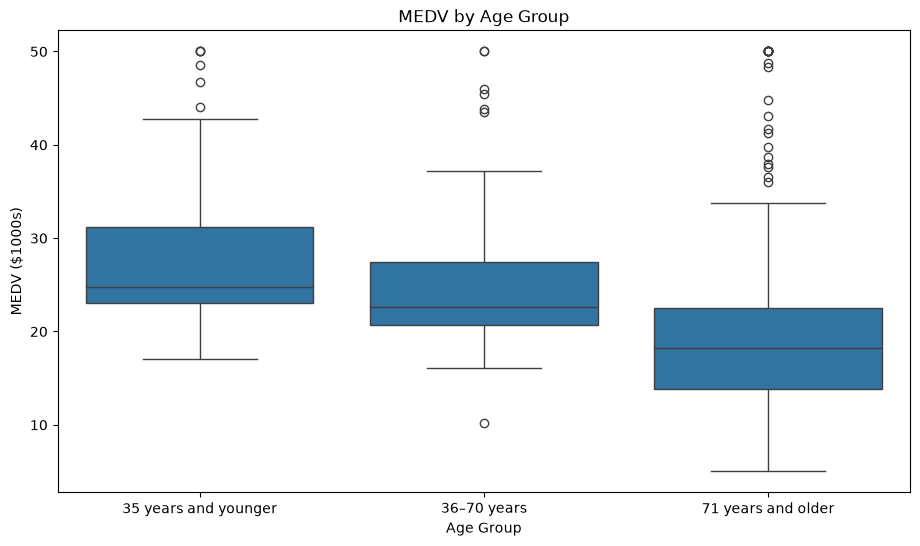

In [32]:

boston_df['age_group'] = pd.cut(
    boston_df['AGE'],
    bins=[0, 35, 70, 100],
    labels=['35 years and younger', '36–70 years', '71 years and older'],
    include_lowest=True
)

plt.figure(figsize=(11, 6))
sns.boxplot(x='age_group', y='MEDV', data=boston_df)
plt.title('MEDV by Age Group')
plt.xlabel('Age Group')
plt.ylabel('MEDV ($1000s)')
plt.show()


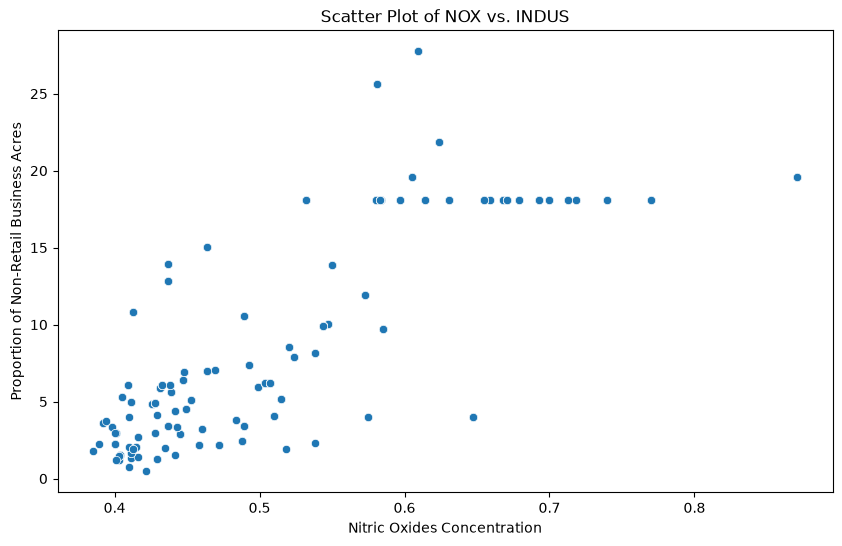

In [33]:

plt.figure(figsize=(10, 6))
sns.scatterplot(x='NOX', y='INDUS', data=boston_df)
plt.title('Scatter Plot of NOX vs. INDUS')
plt.xlabel('Nitric Oxides Concentration')
plt.ylabel('Proportion of Non-Retail Business Acres')
plt.show()


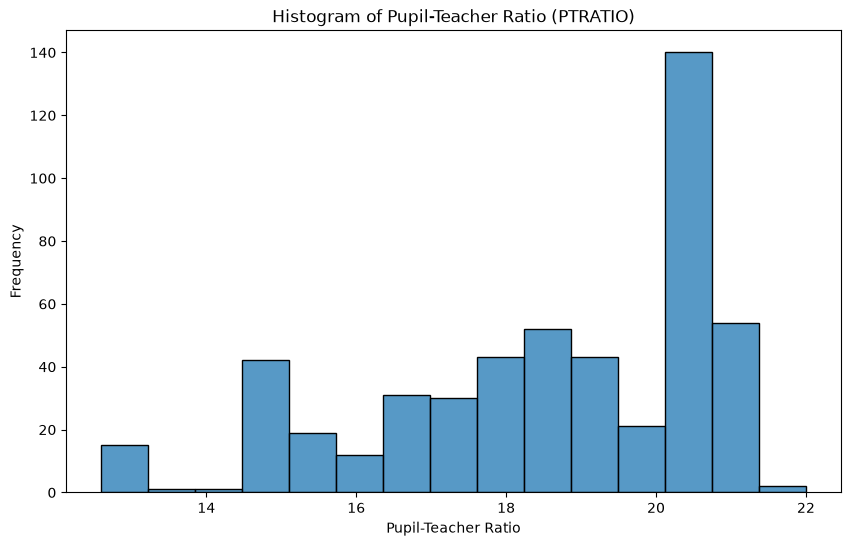

In [34]:

plt.figure(figsize=(10, 6))
sns.histplot(boston_df['PTRATIO'], bins=15)
plt.title('Histogram of Pupil-Teacher Ratio (PTRATIO)')
plt.xlabel('Pupil-Teacher Ratio')
plt.ylabel('Frequency')
plt.show()


In [35]:

from scipy import stats

river = boston_df[boston_df['CHAS'] == 1]['MEDV']
not_river = boston_df[boston_df['CHAS'] == 0]['MEDV']

stat, p_value = stats.levene(river, not_river, center='mean')

print("Levene's Test")
print("Statistic:", stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: The variances are significantly different.")
else:
    print("Fail to reject H0: No significant difference in variances.")


Levene's Test
Statistic: 8.75190489604598
P-value: 0.0032381193676394257
Reject H0: The variances are significantly different.


In [36]:

t_stat, p_value = stats.ttest_ind(
    river,
    not_river,
    equal_var=False
)

print("Welch's T-test")
print("T-statistic:", t_stat)
print("P-value:", p_value)
print("Mean MEDV near river:", river.mean())
print("Mean MEDV away from river:", not_river.mean())

if p_value < 0.05:
    print("Reject H0: Mean MEDV differs significantly between groups.")
else:
    print("Fail to reject H0: No statistically significant difference in mean MEDV.")


Welch's T-test
T-statistic: 3.113291312794837
P-value: 0.003567170098137519
Mean MEDV near river: 28.439999999999998
Mean MEDV away from river: 22.093842887473464
Reject H0: Mean MEDV differs significantly between groups.


In [37]:

group1 = boston_df[boston_df['AGE'] <= 35]['MEDV']
group2 = boston_df[(boston_df['AGE'] > 35) & (boston_df['AGE'] <= 70)]['MEDV']
group3 = boston_df[boston_df['AGE'] > 70]['MEDV']

f_stat, p_value = stats.f_oneway(group1, group2, group3)

print("One-Way ANOVA")
print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one group has a different mean MEDV.")
else:
    print("Fail to reject H0: No statistically significant difference in mean MEDV.")


One-Way ANOVA
F-statistic: 36.40764999196598
P-value: 1.7105011022701524e-15
Reject H0: At least one group has a different mean MEDV.


In [38]:

r, p_value = stats.pearsonr(
    boston_df['NOX'],
    boston_df['INDUS']
)

print("Pearson Correlation Test")
print("Correlation coefficient (r):", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: There is a statistically significant linear relationship.")
else:
    print("Fail to reject H0: No statistically significant linear relationship.")


Pearson Correlation Test
Correlation coefficient (r): 0.7636514469209154
P-value: 7.913361061239734e-98
Reject H0: There is a statistically significant linear relationship.


In [39]:

model = ols('MEDV ~ AGE', data=boston_df).fit()

print("Simple Linear Regression: MEDV ~ AGE")
print(model.summary())

print("\nR-squared:", model.rsquared)
print("Slope coefficient:", model.params['AGE'])
print("P-value for AGE:", model.pvalues['AGE'])

if model.pvalues['AGE'] < 0.05:
    print("Reject H0: The slope is significantly different from zero.")
else:
    print("Fail to reject H0: The slope is not significantly different from zero.")


Simple Linear Regression: MEDV ~ AGE
                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.142
Model:                            OLS   Adj. R-squared:                  0.140
Method:                 Least Squares   F-statistic:                     83.48
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           1.57e-18
Time:                        16:06:46   Log-Likelihood:                -1801.5
No. Observations:                 506   AIC:                             3607.
Df Residuals:                     504   BIC:                             3615.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     3